# Task 3 — Cognitive load and the data-ink ratio
**CLO1.** Data: `car_crashes.csv` (50 states + DC) and `tips.csv`.

`total` = drivers involved in fatal collisions per billion miles. `total`, the percentage columns and the dollar columns are in
three different units, so I plot **only `total`** and never put them on one axis (that would be a Week 1 violation, not a load problem).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# find the data folder whether the notebook sits in assignments/ or one level up
DATA = next(p for p in (Path("data"), Path("assignments/data"), Path("week2/assignments/data")) if p.exists())

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "axes.titlesize": 11,
})
GREY, RED, BLUE = "#bbbbbb", "#ee6677", "#4477aa"

from IPython.display import Markdown, display
import matplotlib.patheffects as pe
cars = pd.read_csv(DATA / "car_crashes.csv")
print(cars.shape, "- missing values:", int(cars.isna().sum().sum()))
cars.head(3)

(51, 8) - missing values: 0


,total,speeding,alcohol,not_distracted,no_previous,ins_premium,ins_losses,abbrev
0,18.8,7.332,5.640,18.048,15.040,784.55,145.08,AL
1,18.1,7.421,4.525,16.290,17.014,1053.48,133.93,AK
2,18.6,6.510,5.208,15.624,17.856,899.47,110.35,AZ


## Step 1 — Build an overloaded chart on purpose
Every bar a different colour, all 51 labels rotated, heavy gridlines in both directions, a thick box frame, a 51-entry legend,
a drop shadow on every bar, and a title that just names the axes.

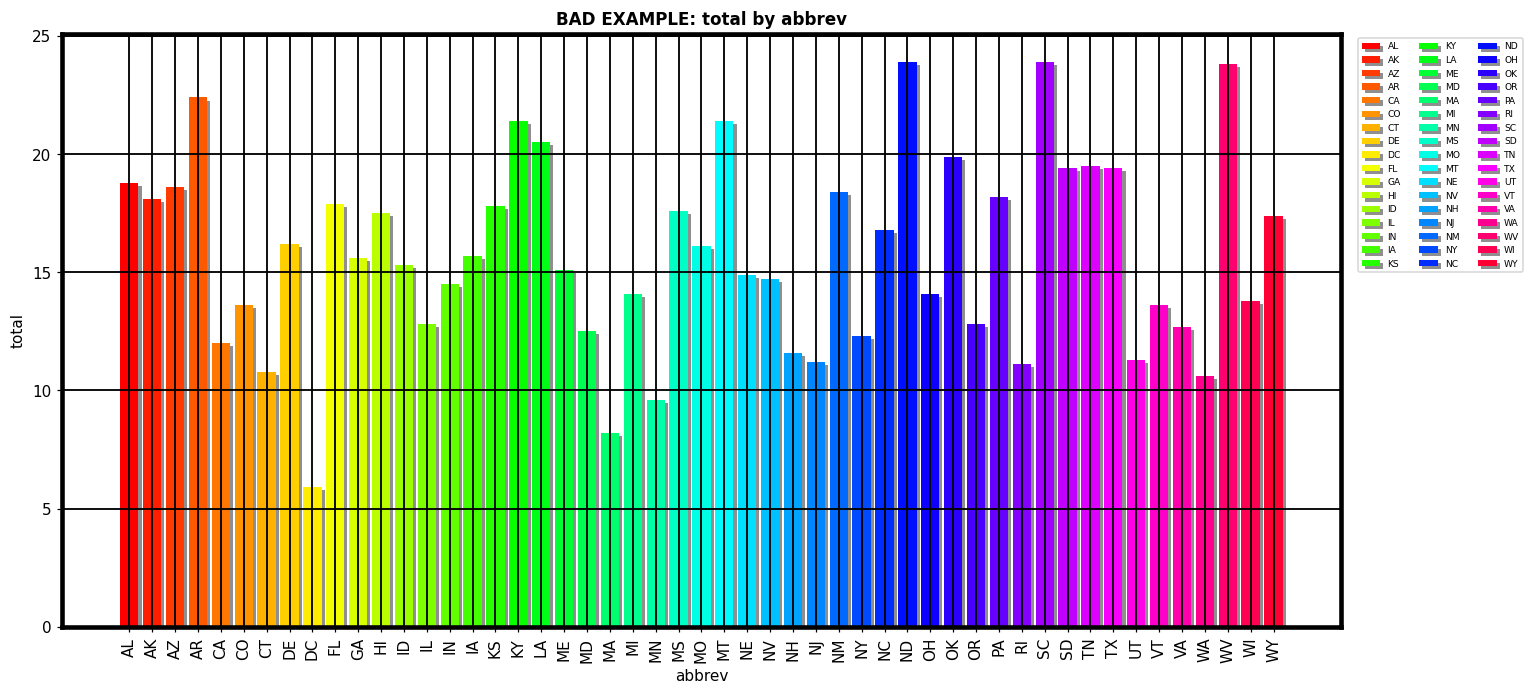

In [2]:
def bad_chart():
    fig, ax = plt.subplots(figsize=(15, 7))
    colours = plt.cm.hsv(np.linspace(0, 1, len(cars), endpoint=False))
    bars = ax.bar(range(len(cars)), cars.total, color=colours, label=None)
    for b, ab in zip(bars, cars.abbrev):
        b.set_label(ab)
        b.set_path_effects([pe.SimplePatchShadow(offset=(2, -2), shadow_rgbFace="#444444", alpha=0.6), pe.Normal()])
    ax.set_xticks(range(len(cars)))
    ax.set_xticklabels(cars.abbrev, rotation=90)
    ax.grid(True, axis="both", color="black", lw=1.2)
    for s in ax.spines.values():
        s.set_visible(True); s.set_linewidth(3)
    ax.legend(ncol=3, fontsize=6, loc="upper left", bbox_to_anchor=(1.01, 1))
    ax.set_xlabel("abbrev"); ax.set_ylabel("total")
    ax.set_title("BAD EXAMPLE: total by abbrev")
    return fig, ax, bars

fig, ax, bars = bad_chart()
fig.savefig("task3_bad_example.png", dpi=200, bbox_inches="tight")
plt.show()

## Step 2 — Count the load
**Classification of every element** (Sweller's three kinds):

| Element | Load | Why |
|---|---|---|
| 51 bars (length = `total`) | **Intrinsic** | These *are* the data: 51 values the reader has to compare. This load cannot be removed, only sequenced. |
| y-axis ticks and scale | **Germane** | Lets the reader convert bar length to a number. Effort spent understanding, so protect it. |
| 51 state abbreviations | **Intrinsic** as content (which state is it?), **extraneous** as rendered | Identity is part of the data, but 90°-rotated text forces head-tilting and slow reading. |
| 51 different bar colours | **Extraneous** | Colour encodes nothing the x position and label do not already say. It also invites the reader to look for a meaning that is not there. |
| 51-entry legend | **Extraneous** | Duplicates the x labels. The reader must match a colour from the legend to a bar: a pure memory task. |
| Vertical gridlines (51) | **Extraneous** | Bars already sit on a discrete axis; vertical lines carry no value. |
| Heavy horizontal gridlines | **Germane in moderation, extraneous at this weight** | Light gridlines help read values; thick black ones compete with the bars. |
| Thick box frame (4 spines) | **Extraneous** | Encloses the chart in a box that groups nothing. |
| Drop shadows | **Extraneous** | Pure decoration, and it fakes a 3-D depth the data do not have. |
| Title "total by abbrev" | **Extraneous** | Names the axes instead of stating a finding, so the reader has to do the interpretation. |
| Axis labels `abbrev`, `total` | **Extraneous** | Uninformative labels and no units. A good label would add germane load back (see Step 5). |

**Data-ink ratio, working shown.** I count every drawn mark straight from the matplotlib figure, so the number is not
a guess. "Data ink" = marks that encode a number. I report two counts: a strict one (only the 51 bars) and a generous one (bars +
y-axis tick labels and the y label, because they carry the scale).

In [3]:
n_bars = len(bars)
x_ticklabels = len(ax.get_xticklabels())
y_ticks = [t for t in ax.get_yticks() if ax.get_ylim()[0] <= t <= ax.get_ylim()[1]]
ink = {
    "bars (encode a number)": n_bars,
    "x tick labels": x_ticklabels,
    "x tick marks": len(ax.get_xticks()),
    "y tick labels": len(y_ticks),
    "y tick marks": len(y_ticks),
    "vertical gridlines": len(ax.get_xticks()),
    "horizontal gridlines": len(y_ticks),
    "frame (spines)": 4,
    "legend swatches": n_bars,
    "legend text entries": n_bars,
    "drop shadows": n_bars,
    "title + 2 axis labels": 3,
}
ink_df = pd.Series(ink, name="marks").to_frame()
display(ink_df)
total = ink_df.marks.sum()
strict = n_bars
generous = n_bars + len(y_ticks) + 1            # + y tick labels + y-axis label
display(Markdown(
    f"**Total marks = {total}.**  \n"
    f"Strict data-ink ratio = {strict} / {total} = **{strict/total:.2f}**  \n"
    f"Generous (bars + {len(y_ticks)} y tick labels + y label) = {generous} / {total} = **{generous/total:.2f}**"))

,marks
bars (encode a number),51
x tick labels,51
x tick marks,51
y tick labels,6
y tick marks,6
vertical gridlines,51
horizontal gridlines,6
frame (spines),4
legend swatches,51
legend text entries,51


**Total marks = 382.**  
Strict data-ink ratio = 51 / 382 = **0.13**  
Generous (bars + 6 y tick labels + y label) = 58 / 382 = **0.15**

So only about 13–15% of this chart's ink encodes or explains a number; the other ~85% is load the reader has to look past.

## Step 3 — Strip it down, one panel per step (five panels)
Order used: (1) remove the legend → (2) remove the frame, the vertical gridlines and the shadows → (3) single hue →
(4) sort the bars → (5) label only what matters. Panels 1–4 each build on the previous one.
Step 2 bundles frame, vertical grid and shadow because all three are extraneous decoration and the brief allows removing the frame together with one gridline axis; shadows are a third removal I add so the shadow does not carry through to later panels.

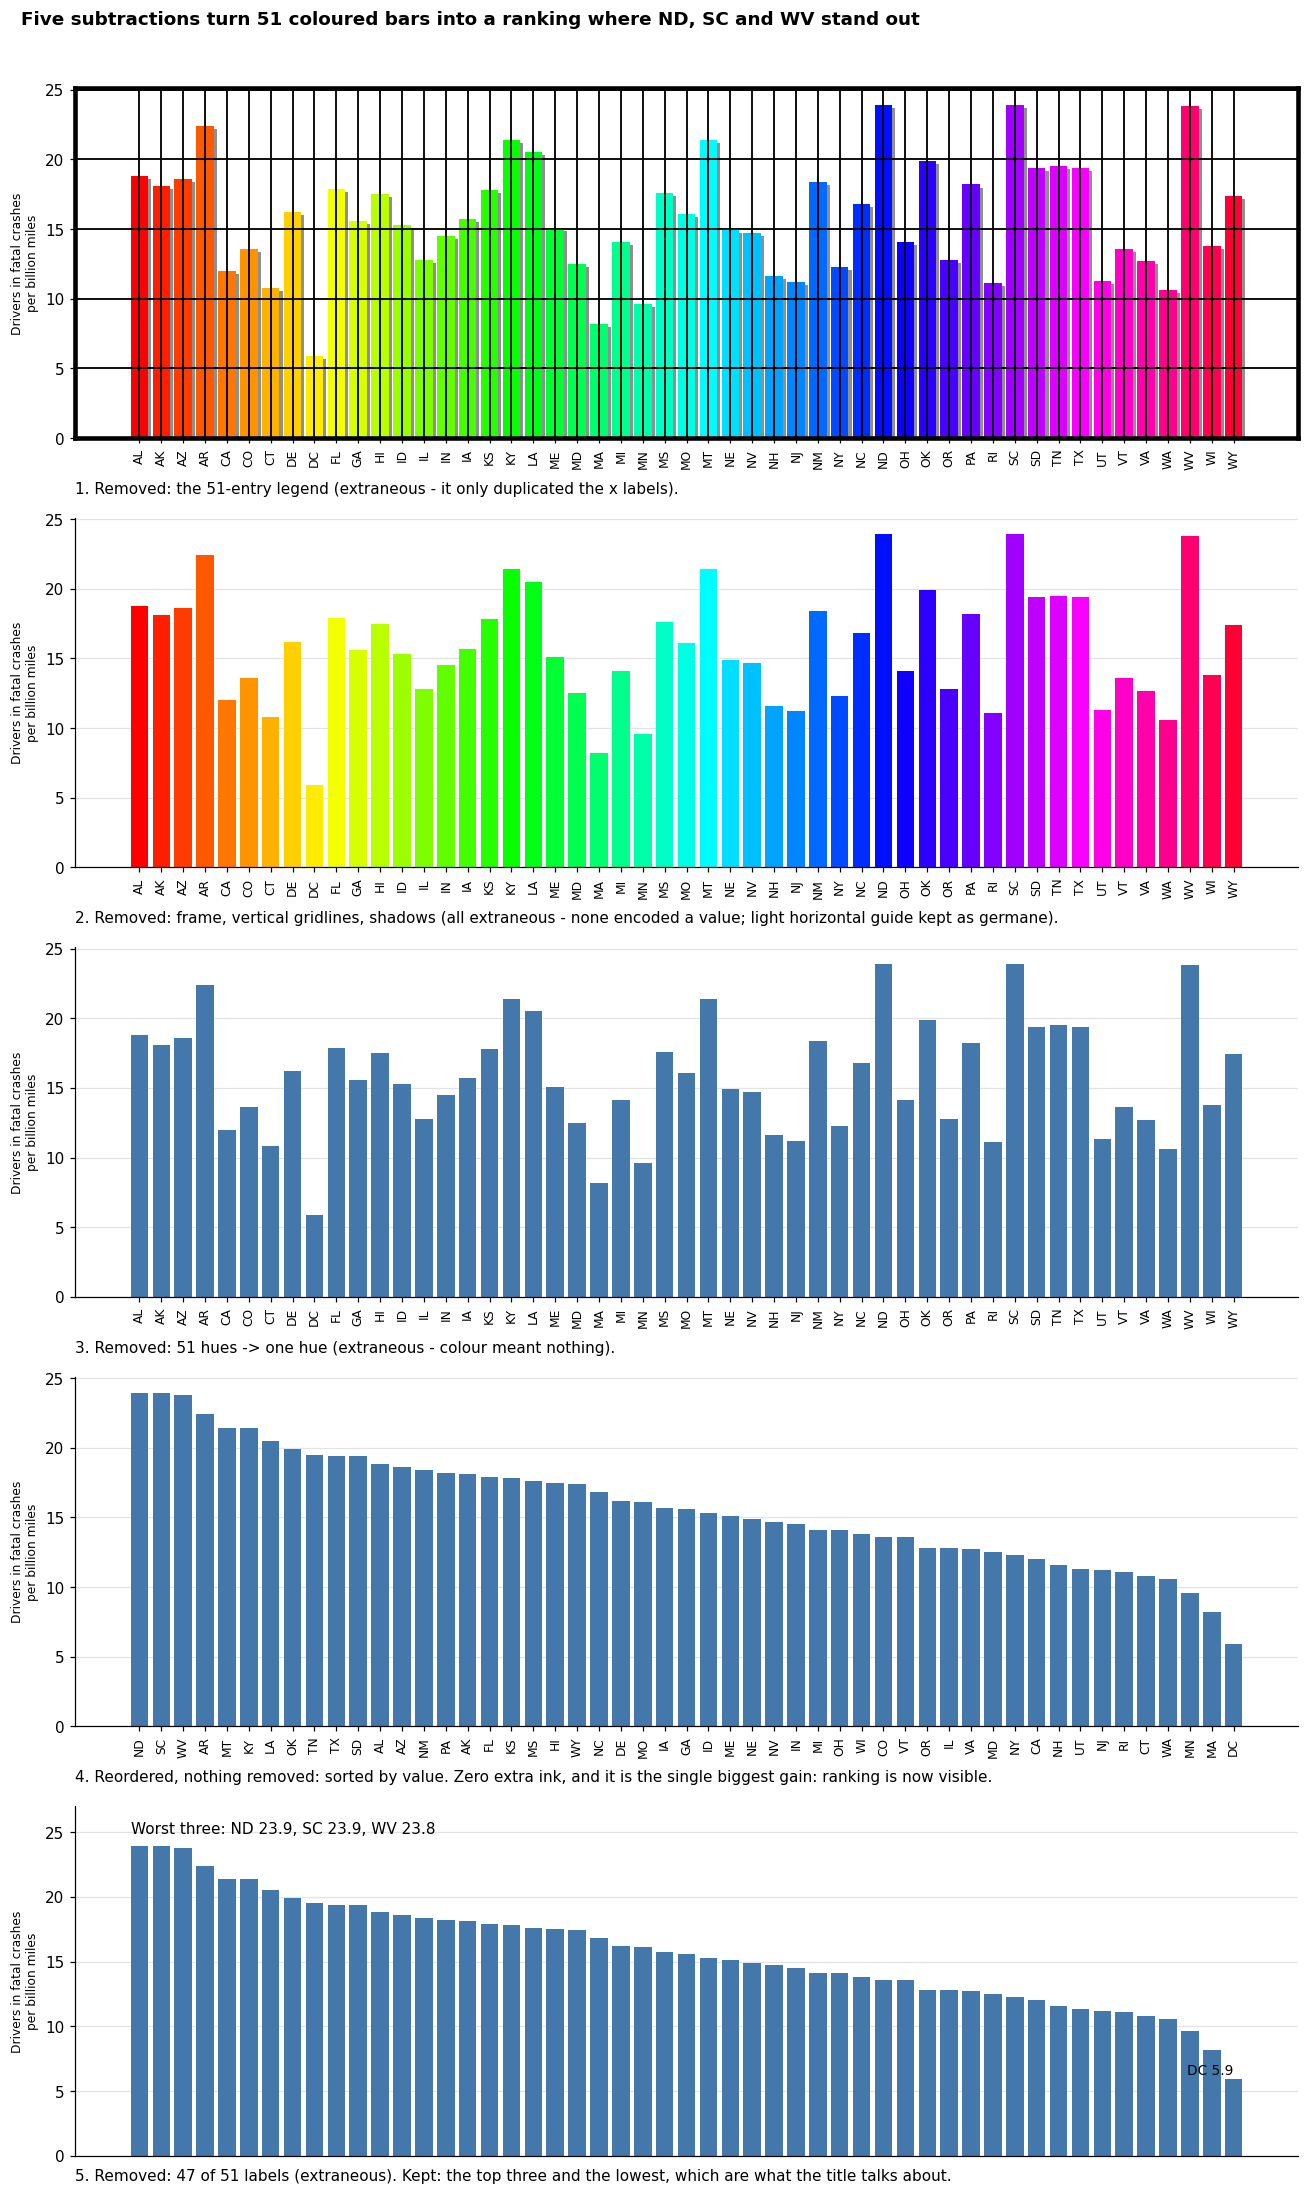

In [4]:
ranked = cars.sort_values("total", ascending=False).reset_index(drop=True)
top3 = ranked.head(3)
rainbow = plt.cm.hsv(np.linspace(0, 1, len(cars), endpoint=False))

def stage(ax, k):
    d = cars if k < 4 else ranked
    cols = rainbow if k < 3 else BLUE
    bars = ax.bar(range(len(d)), d.total, color=cols if k < 3 else BLUE, width=0.8 if k >= 2 else 0.8)
    if k < 2:   # shadows still on
        for b in bars:
            b.set_path_effects([pe.SimplePatchShadow(offset=(2, -2), shadow_rgbFace="#444444", alpha=0.6), pe.Normal()])
    ax.set_xticks(range(len(d)))
    ax.set_xticklabels(d.abbrev, rotation=90, fontsize=8)
    ax.set_ylabel("Drivers in fatal crashes\nper billion miles", fontsize=8)
    if k < 2:   # frame + both gridlines still on
        ax.grid(True, axis="both", color="black", lw=1.2)
        for s in ax.spines.values(): s.set_visible(True); s.set_linewidth(3)
    else:       # frame off, vertical gridlines off, light horizontal guide kept
        ax.grid(True, axis="y", color="#e3e3e3", lw=0.8); ax.set_axisbelow(True)
        for s in ("top", "right"): ax.spines[s].set_visible(False)
    if k == 5:  # label only what matters
        ax.set_xticks([]); 
        ax.set_ylim(0, 27)
        ax.text(-0.4, top3.total.max() + 1.0,
                "Worst three: " + ", ".join(f"{r.abbrev} {r.total:.1f}" for _, r in top3.iterrows()),
                ha="left", fontsize=10)
        low = ranked.iloc[-1]
        ax.text(len(ranked) - 1, low.total + 0.4, f"{low.abbrev} {low.total:.1f}", ha="right", fontsize=9)

captions = [
    "1. Removed: the 51-entry legend (extraneous - it only duplicated the x labels).",
    "2. Removed: frame, vertical gridlines, shadows (all extraneous - none encoded a value; light horizontal guide kept as germane).",
    "3. Removed: 51 hues -> one hue (extraneous - colour meant nothing).",
    "4. Reordered, nothing removed: sorted by value. Zero extra ink, and it is the single biggest gain: ranking is now visible.",
    "5. Removed: 47 of 51 labels (extraneous). Kept: the top three and the lowest, which are what the title talks about.",
]
fig, axes = plt.subplots(5, 1, figsize=(12, 20))
for k, (ax, cap) in enumerate(zip(axes, captions), start=1):
    stage(ax, k)
    ax.set_xlabel(cap, loc="left", fontsize=10, labelpad=8)
fig.suptitle(f"Five subtractions turn 51 coloured bars into a ranking where {top3.abbrev.iloc[0]}, {top3.abbrev.iloc[1]} and {top3.abbrev.iloc[2]} stand out",
             x=0.02, ha="left", fontweight="bold", y=0.995)
fig.tight_layout(rect=(0, 0, 1, 0.985))
fig.savefig("task3_five_panel_strip.png", dpi=200, bbox_inches="tight")
plt.show()

**What I notice.** Panel 4 removed *nothing* and added no ink — it only changed the order — yet it is the biggest single
improvement. Before sorting, the reader has to scan 51 bars to find the tallest; after sorting, the tallest sits at the left edge
and the answer to "which states are worst?" is read off immediately. Ordering turns a search problem into a glance: the eye uses
position along a monotone sequence (the top-ranked channel) instead of scanning for a maximum.

## Step 4 — Respect the 4 ± 1 limit
Fifty-one separate bars exceed working memory several times over. I chunk the states into the four Census regions, so the reader
holds **4 things**: Northeast, Midwest, South, West. The pop-out is the region with the highest average.

,mean,low,high,n,within_range
region,,,,,
South,17.9,5.9,23.9,17,18.0
Midwest,15.6,9.6,23.9,12,14.3
West,15.5,10.6,21.4,13,10.8
Northeast,12.5,8.2,18.2,9,10.0


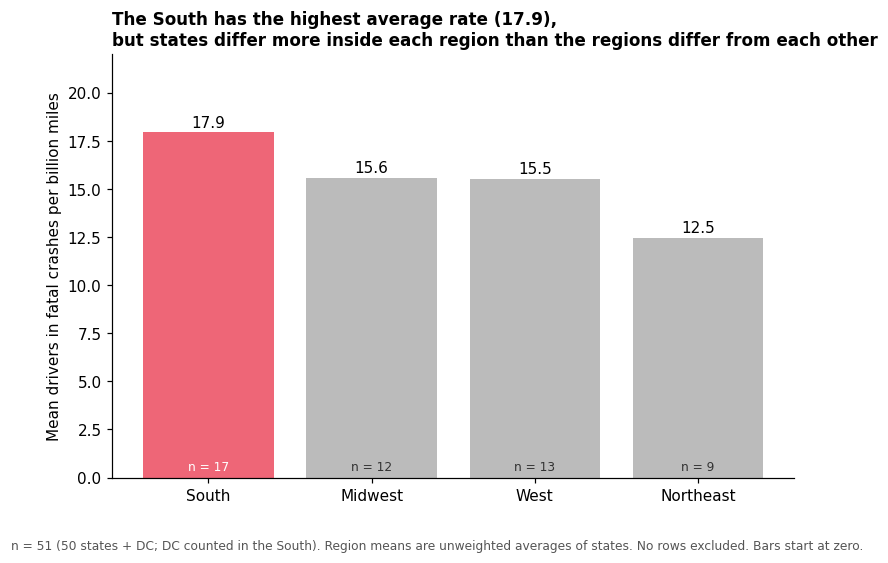

In [5]:
REGIONS = {
    "Northeast": "CT ME MA NH RI VT NJ NY PA",
    "Midwest":   "IL IN MI OH WI IA KS MN MO NE ND SD",
    "South":     "DE FL GA MD NC SC VA WV AL KY MS TN AR LA OK TX DC",
    "West":      "AZ CO ID MT NV NM UT WY AK CA HI OR WA",
}
state_region = {a: r for r, s in REGIONS.items() for a in s.split()}
assert set(state_region) == set(cars.abbrev), "region map must cover exactly the 51 rows"
cars["region"] = cars.abbrev.map(state_region)

reg = cars.groupby("region").total.agg(mean="mean", low="min", high="max", n="size")
reg["within_range"] = reg.high - reg.low
reg = reg.sort_values("mean", ascending=False)
between_gap = reg["mean"].max() - reg["mean"].min()
assert reg.within_range.min() > between_gap, "title claim must hold in the data"
display(reg.round(1))

top_region = reg.index[0]
fig, ax = plt.subplots(figsize=(8, 5))
colours = [RED if r == top_region else GREY for r in reg.index]
ax.bar(reg.index, reg["mean"], color=colours)
for i, (r, row) in enumerate(reg.iterrows()):
    ax.text(i, row["mean"] + 0.3, f"{row['mean']:.1f}", ha="center")
    ax.text(i, 0.4, f"n = {int(row.n)}", ha="center", fontsize=8, color="white" if r == top_region else "#333333")
ax.set_ylabel("Mean drivers in fatal crashes per billion miles")
ax.set_ylim(0, 22)
ax.set_title(f"The {top_region} has the highest average rate ({reg['mean'].iloc[0]:.1f}),\n"
             f"but states differ more inside each region than the regions differ from each other", loc="left")
fig.text(0.01, -0.02, "n = 51 (50 states + DC; DC counted in the South). Region means are unweighted averages of states. No rows excluded. Bars start at zero.",
         fontsize=8, color="#555555")
fig.savefig("task3_four_chunks.png", dpi=200, bbox_inches="tight")
plt.show()

**Chunking chosen:** four Census regions, mean of the member states.

**What it costs.** Every chunking hides something, and this one hides the thing that matters most: the **spread inside each
region**. The table above shows the within-region range (highest state minus lowest state) is larger in every region than the whole
gap between region averages. A reader who only sees the four bars would conclude "regions differ" when the bigger story is "states
within a region differ". It also buries individual states (the worst states and the best, DC, are no longer visible), and it makes
a state's region assignment an assumption (DC is counted in the South).

## Step 5 — Over-strip it
Now remove too much: no axis labels, no tick values, no units, no state names. The bars are sorted and one hue, but the reader
cannot tell what they are measuring or how much.

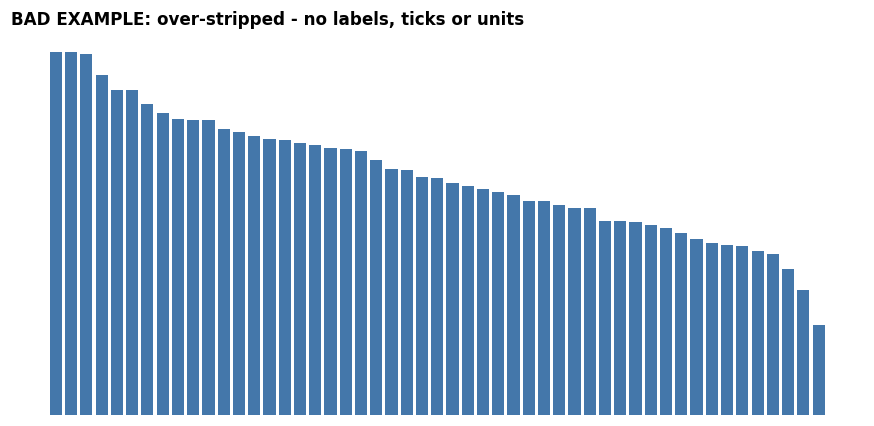

In [6]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(range(len(ranked)), ranked.total, color=BLUE)
ax.axis("off")
ax.set_title("BAD EXAMPLE: over-stripped - no labels, ticks or units", loc="left", color="black")
fig.savefig("task3_over_stripped_bad.png", dpi=200, bbox_inches="tight")
plt.show()

**Why "maximise data-ink" fails blindly.** This chart has a data-ink ratio near 1 (almost every mark is a bar), but it is
useless: the reader cannot say what is measured, which bar is which state, or whether the tallest bar is twice or ten times the
shortest. The y-axis, units and the few labels are not "non-data ink" in any useful sense — they are the information that makes
the bars *interpretable*, i.e. germane load that must be protected.

**Stopping rule for a colleague (one sentence):** *Keep deleting until the next deletion would force the reader to ask what is
being measured, in what units, or which mark is which; every remaining element must carry a number or save the reader a lookup.*

## The question to answer — a `tips.csv` chart where *adding* ink lowers cognitive load
Scatter of tip against bill. Without a reference line the reader has to estimate "tip ÷ bill" for each dot in their head (a
ratio judgement, which is slow and inaccurate). Adding **one line at 15%** does the arithmetic once: dots above it tipped more
than 15%, dots below tipped less. I use one strong colour only on that line; the dots stay grey.

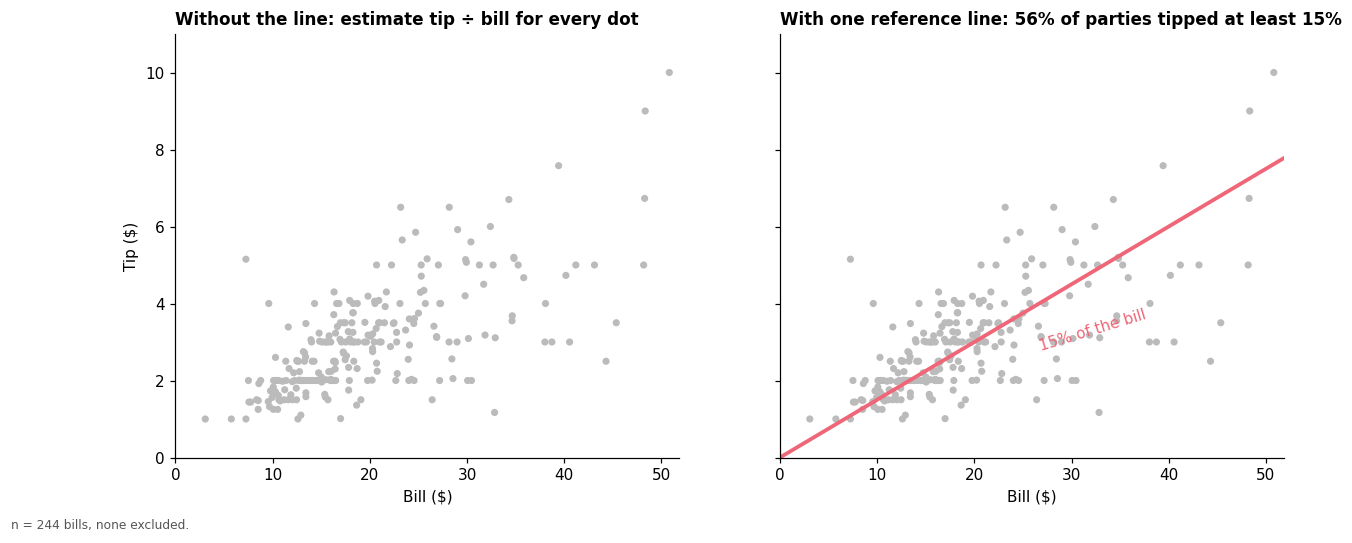

In [7]:
tips = pd.read_csv(DATA / "tips.csv")
tips["pct"] = tips.tip / tips.total_bill * 100
share15 = (tips.pct >= 15).mean()
xmax = tips.total_bill.max() * 1.02

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True, sharex=True)
for ax in axes:
    ax.scatter(tips.total_bill, tips.tip, s=22, color=GREY, edgecolors="none")
    ax.set_xlabel("Bill ($)")
axes[0].set_ylabel("Tip ($)")
axes[0].set_title("Without the line: estimate tip ÷ bill for every dot", loc="left")
axes[1].plot([0, xmax], [0, 0.15 * xmax], color=RED, lw=2.5)
axes[1].text(xmax * 0.62, 0.15 * xmax * 0.62 - 0.9, "15% of the bill", color=RED, rotation=17, ha="center", va="top")
axes[1].set_title(f"With one reference line: {share15:.0%} of parties tipped at least 15%", loc="left")
axes[0].set_xlim(0, xmax)
axes[0].set_ylim(0, 11)
fig.text(0.01, -0.02, f"n = {len(tips)} bills, none excluded.", fontsize=8, color="#555555")
fig.savefig("task3_tips_added_ink.png", dpi=200, bbox_inches="tight")
plt.show()

**Why the extra ink lowers load.** The line is a few extra pixels but it replaces roughly 244 mental divisions with one
comparison *above/below*. That work has moved from the reader's working memory (a slow ratio estimate) to the pre-attentive
system (position relative to a line, which is among the fastest comparisons we make). The line is also direct-labelled, so there is no legend to
decode.

**So data-ink maximisation is a heuristic, not a rule.** "Delete ink that carries no information" is a good default because most
decoration is extraneous load. But the real objective is *less total effort for the reader*, and sometimes the lowest-effort chart
contains ink that does not itself encode a data value: a reference line, an annotation, a direct label. Tufte's ratio measures
how much ink shows data; it cannot see the thinking the reader is spared.